In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
X = df[['SALES', 'QUANTITYORDERED']]
sc = StandardScaler()
X = sc.fit_transform(X)

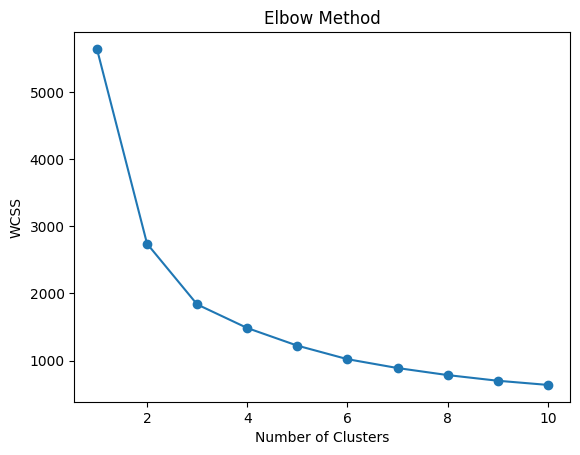

In [4]:
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()


     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30               1
1  2765.90               34               2
2  3884.34               41               2
3  3746.70               45               2
4  5205.27               49               0


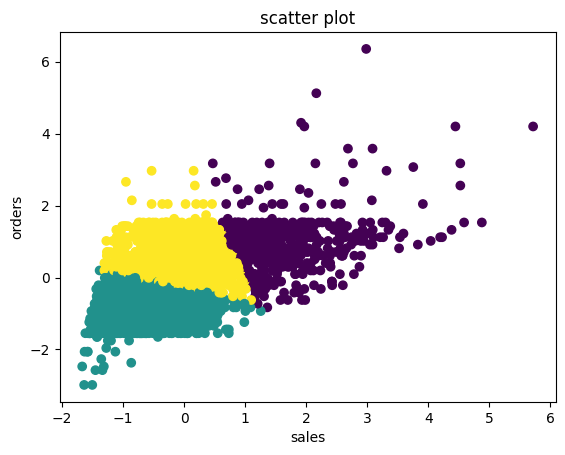

In [6]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = km.fit_predict(X)
print(df[['SALES', 'QUANTITYORDERED', 'KMeans_Cluster']].head())
plt.scatter(X[:,0],X[:,1],c=df['KMeans_Cluster'])
plt.title("scatter plot")
plt.xlabel("sales")
plt.ylabel("orders")
plt.show()

     SALES  QUANTITYORDERED  Hierarchical_Cluster
0  2871.00               30                     0
1  2765.90               34                     0
2  3884.34               41                     0
3  3746.70               45                     2
4  5205.27               49                     1


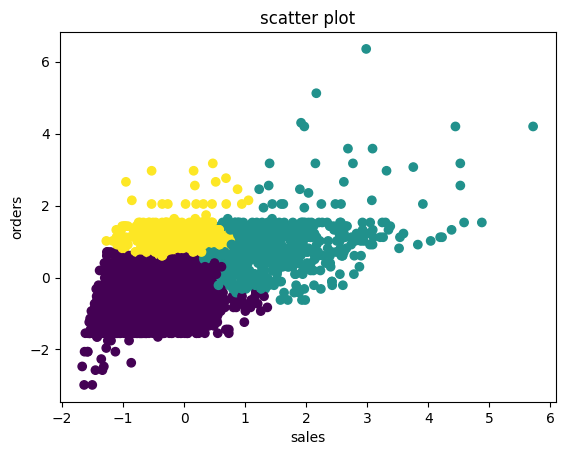

In [7]:
hc = AgglomerativeClustering(n_clusters=3)
df['Hierarchical_Cluster'] = hc.fit_predict(X)

print(df[['SALES', 'QUANTITYORDERED', 'Hierarchical_Cluster']].head())

plt.scatter(X[:,0],X[:,1],c=df['Hierarchical_Cluster'])
plt.title("scatter plot")
plt.xlabel("sales")
plt.ylabel("orders")
plt.show()

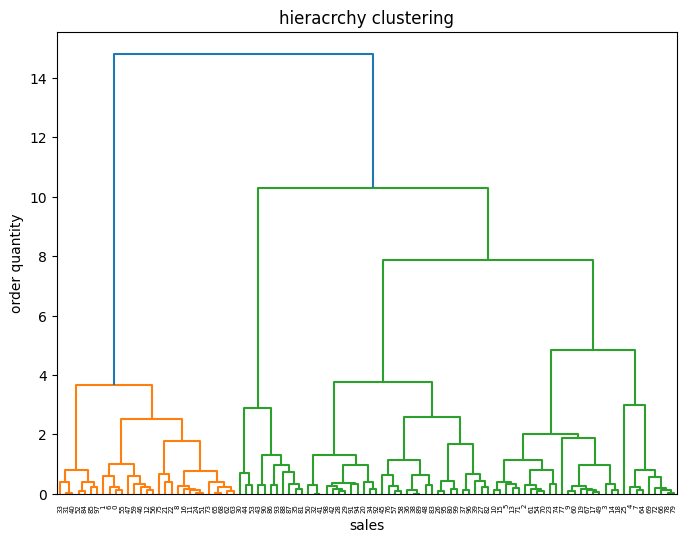

In [15]:
from scipy.cluster.hierarchy import dendrogram,linkage
Z=linkage(X[:100], method="ward")

plt.figure(figsize=(8,6))
dendrogram(Z)
plt.title("hieracrchy clustering")
plt.xlabel("sales")
plt.ylabel("order quantity")
plt.show()